In [1]:
import os, pathlib, shutil, subprocess, sys, time, urllib.request

import numpy as np
import matplotlib.pyplot as plt          # BEFORE torch in this environment (see the warning above)
import uproot, awkward as ak, vector
import torch
import torch.nn as nn
import json
from pathlib import Path
vector.register_awkward()

torch.manual_seed(42)
np.random.seed(42)

print("python:", sys.version.split()[0])
print("kernel:", sys.executable, "\n")
for name in ["torch", "sklearn", "uproot", "awkward", "vector", "numpy", "matplotlib", "json"]:
    try:
        mod = __import__(name)
        print(f"  [ok]      {name:<10s} {getattr(mod, '__version__', '?')}")
    except ImportError:
        print(f"  [MISSING] {name}")

python: 3.10.14
kernel: /depot/cms/conda_envs/bhanda25/Coffea-Santosh/bin/python 

  [ok]      torch      1.11.0+cu102
  [ok]      sklearn    1.5.1
  [ok]      uproot     5.3.10
  [ok]      awkward    2.6.5
  [ok]      vector     1.4.1
  [ok]      numpy      1.26.4
  [ok]      matplotlib 3.9.1
  [ok]      json       2.0.9


In [2]:
DATA_DIR = Path.cwd()

SIGNAL = DATA_DIR / "HiggsSignal.json"
BACKGROUND = DATA_DIR / "HiggsBackground.json"

with open(SIGNAL, "r") as f:
     index = json.load(f)

with open(BACKGROUND, "r") as f:
     indexb = json.load(f)

# Use the original XRootD URLs
signal_urls = [file["uri"] for file in index["files"]]
background_urls = [file["uri"] for file in indexb["files"]]

branches = [
     "Muon_pt",
     "Muon_eta",
     "Muon_phi",
     "Muon_mass",
     "Muon_charge",
     "Muon_pfRelIso04_all",
     "Muon_dxy",
     "Muon_dxyErr",
     "Muon_dz",
     "Muon_dzErr"
]


signal_arrays = []

for i, url in enumerate(signal_urls):
     print(f"Reading file {i+1}/{len(signal_urls)}")

     with uproot.open(url) as f:
         data = f["Events"].arrays(branches, library="ak")
         signal_arrays.append(data)


background_arrays = []

for i, url in enumerate(background_urls):
     print(f"Reading file {i+1}/{len(background_urls)}")

     with uproot.open(url) as f:
         data = f["Events"].arrays(branches, library="ak")
         background_arrays.append(data)

signal_data = ak.concatenate(signal_arrays)
background_data = ak.concatenate(background_arrays)

Reading file 1/8
Reading file 2/8
Reading file 3/8
Reading file 4/8
Reading file 5/8
Reading file 6/8
Reading file 7/8
Reading file 8/8
Reading file 1/15
Reading file 2/15
Reading file 3/15
Reading file 4/15
Reading file 5/15
Reading file 6/15
Reading file 7/15
Reading file 8/15
Reading file 9/15
Reading file 10/15
Reading file 11/15
Reading file 12/15
Reading file 13/15
Reading file 14/15
Reading file 15/15


In [3]:
BRANCHES = branches
M_Z = 91.1876
FEATURE_NAMES = ["m4mu", "pt4mu", "absEta4mu", "mZ1", "mZ2", "ptZ1", "ptZ2",
                 "dR_Z1", "dR_Z2", "dR_Z1Z2", "pt1", "pt2", "pt3", "pt4"]

def build_features(path):
    raw = uproot.open(path)["Events"].arrays(BRANCHES)

    muons = ak.zip({
        "pt": raw.Muon_pt, "eta": raw.Muon_eta, "phi": raw.Muon_phi, "mass": raw.Muon_mass,
        "charge": raw.Muon_charge, "iso": raw.Muon_pfRelIso04_all,
        "dxy_sig": abs(raw.Muon_dxy / raw.Muon_dxyErr),
        "dz_sig":  abs(raw.Muon_dz  / raw.Muon_dzErr),
    }, with_name="Momentum4D")

    # --- Lab 1 selection -------------------------------------------------
    muons = muons[(muons.pt > 5) & (abs(muons.eta) < 2.4) & (muons.iso < 0.40)
                  & (muons.dxy_sig < 4) & (muons.dz_sig < 4)]
    ev = muons[ak.num(muons) == 4]
    ev = ev[ak.sum(ev.charge, axis=1) == 0]
    ev = ev[ak.argsort(ev.pt, ascending=False)]          # sort by pT: this sample is NOT pre-sorted

    # --- new: thresholds on the two hardest muons -------------------------
    ev = ev[(ev[:, 0].pt > 20) & (ev[:, 1].pt > 10)]

    # --- pair the muons into two Z candidates ----------------------------
    idx   = ak.local_index(ev)
    pairs = ak.argcombinations(ev, 2, fields=["i", "j"])
    os_p  = pairs[(ev.charge[pairs.i] + ev.charge[pairs.j]) == 0]

    zcand = ev[os_p.i] + ev[os_p.j]
    best  = ak.argmin(abs(zcand.mass - M_Z), axis=1, keepdims=True)   # Z1 = closest to m_Z

    i1, j1 = ak.flatten(os_p.i[best]), ak.flatten(os_p.j[best])
    Z1     = ak.flatten(zcand[best])
    dR_Z1  = ak.flatten(ev[os_p.i].deltaR(ev[os_p.j])[best])

    rest = ev[(idx != i1) & (idx != j1)]                 # the other two muons
    assert ak.all(ak.num(rest) == 2), "leftover muons must be exactly 2"
    Z2 = rest[:, 0] + rest[:, 1]

    four = ev[:, 0] + ev[:, 1] + ev[:, 2] + ev[:, 3]

    feats = {
        "m4mu":      four.mass,          # invariant mass of the whole system
        "pt4mu":     four.pt,
        "absEta4mu": abs(four.eta),
        "mZ1":       Z1.mass,            # the on-shell-ish Z
        "mZ2":       Z2.mass,            # the off-shell Z*
        "ptZ1":      Z1.pt,
        "ptZ2":      Z2.pt,
        "dR_Z1":     dR_Z1,              # opening angle inside Z1
        "dR_Z2":     rest[:, 0].deltaR(rest[:, 1]),
        "dR_Z1Z2":   Z1.deltaR(Z2),      # angle between the two Z bosons
        "pt1":       ev[:, 0].pt,        # the four muon pT, hardest first
        "pt2":       ev[:, 1].pt,
        "pt3":       ev[:, 2].pt,
        "pt4":       ev[:, 3].pt,
    }
    return {k: ak.to_numpy(v).astype(np.float32) for k, v in feats.items()}

def build_all(urls):
    parts = []
    for i, url in enumerate(urls):
        print(f"Processing file {i+1}/{len(urls)}")
        parts.append(build_features(url))
    return {k: np.concatenate([p[k] for p in parts]) for k in FEATURE_NAMES}

data = {
    "background": build_all(background_urls),
    "signal":     build_all(signal_urls),
}

print(f"{len(FEATURE_NAMES)} features defined")

Processing file 1/15
Processing file 2/15
Processing file 3/15
Processing file 4/15
Processing file 5/15
Processing file 6/15
Processing file 7/15
Processing file 8/15
Processing file 9/15
Processing file 10/15
Processing file 11/15
Processing file 12/15
Processing file 13/15
Processing file 14/15
Processing file 15/15
Processing file 1/8
Processing file 2/8
Processing file 3/8
Processing file 4/8
Processing file 5/8
Processing file 6/8
Processing file 7/8
Processing file 8/8
14 features defined


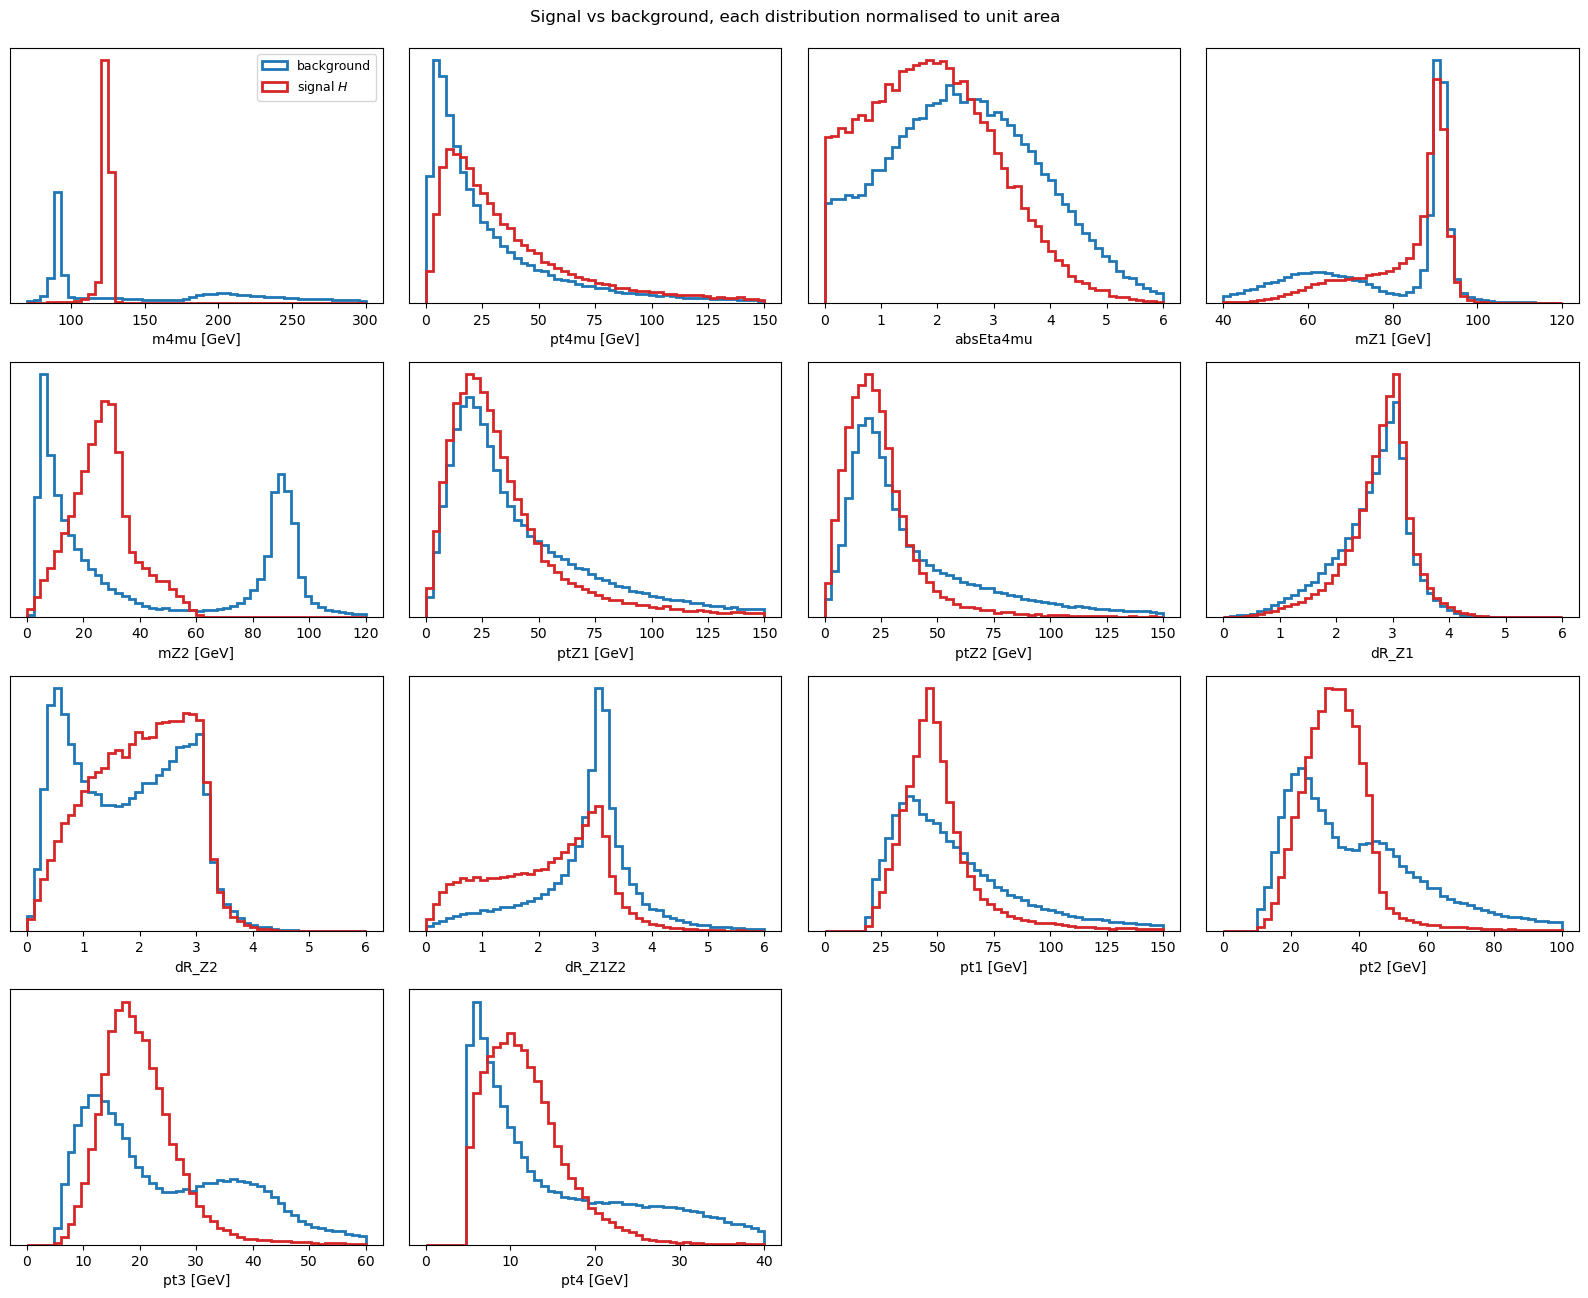

In [4]:
RANGES = {"m4mu": (70, 300), "pt4mu": (0, 150), "absEta4mu": (0, 6), "mZ1": (40, 120),
          "mZ2": (0, 120), "ptZ1": (0, 150), "ptZ2": (0, 150), "dR_Z1": (0, 6),
          "dR_Z2": (0, 6), "dR_Z1Z2": (0, 6), "pt1": (0, 150), "pt2": (0, 100),
          "pt3": (0, 60), "pt4": (0, 40)}

fig, axes = plt.subplots(4, 4, figsize=(16, 13))
for ax, name in zip(axes.flat, FEATURE_NAMES):
    lo, hi = RANGES[name]
    bins = np.linspace(lo, hi, 51)                       # 50 bins
    ax.hist(data["background"][name], bins=bins, histtype="step", lw=2,
            density=True, label="background", color="tab:blue")
    ax.hist(data["signal"][name], bins=bins, histtype="step", lw=2,
            density=True, label="signal $H$", color="tab:red")
    ax.set_xlabel(name + ("" if name.startswith(("dR", "abs", "massAsym")) else " [GeV]"))
    ax.set_yticks([])
for ax in axes.flat[len(FEATURE_NAMES):]:
    ax.axis("off")
axes.flat[0].legend(fontsize=9)
fig.suptitle("Signal vs background, each distribution normalised to unit area", y=0.995)
plt.tight_layout(); plt.show()

In [5]:
def stack_samples(data, feature_names, balance=True, seed=42):
    rng = np.random.default_rng(seed)

    Xs = np.stack([data["signal"][f]     for f in feature_names], axis=1)
    Xb = np.stack([data["background"][f] for f in feature_names], axis=1)

    if balance:
        keep = rng.permutation(len(Xb))[:len(Xs)]
        Xb   = Xb[keep]

    X = np.concatenate([Xs, Xb]).astype(np.float32)
    y = np.concatenate([np.ones(len(Xs)), np.zeros(len(Xb))]).astype(np.float32)

    shuffle = rng.permutation(len(X))          # ESSENTIAL: otherwise all signal comes first
    return X[shuffle], y[shuffle]


X_all, y_all = stack_samples(data, FEATURE_NAMES)
print("X:", X_all.shape, " y:", y_all.shape)
print(f"class balance: {y_all.sum():.0f} signal / {len(y_all)-y_all.sum():.0f} background")

X: (94450, 14)  y: (94450,)
class balance: 47225 signal / 47225 background


In [6]:
n = len(X_all)
i_train, i_val = int(0.60 * n), int(0.80 * n)

X_train, y_train = X_all[:i_train],      y_all[:i_train]
X_val,   y_val   = X_all[i_train:i_val], y_all[i_train:i_val]
X_test,  y_test  = X_all[i_val:],        y_all[i_val:]

mean = X_train.mean(axis=0)        # <-- TRAINING SET ONLY
std  = X_train.std(axis=0)

def standardise(X):
    return (X - mean) / std

Xtr = torch.tensor(standardise(X_train)); ytr = torch.tensor(y_train).reshape(-1, 1)
Xva = torch.tensor(standardise(X_val));   yva = torch.tensor(y_val).reshape(-1, 1)
Xte = torch.tensor(standardise(X_test));  yte = torch.tensor(y_test).reshape(-1, 1)

n_features = Xtr.shape[1]
print(f"train {len(Xtr):>6,}   val {len(Xva):>6,}   test {len(Xte):>6,}   features {n_features}")
print(f"\nafter standardising, training features have")
print(f"  mean in [{Xtr.mean(0).min():+.2e}, {Xtr.mean(0).max():+.2e}]")
print(f"  std  in [{Xtr.std(0).min():.3f}, {Xtr.std(0).max():.3f}]")

train 56,670   val 18,890   test 18,890   features 14

after standardising, training features have
  mean in [-1.74e-05, +1.71e-05]
  std  in [1.000, 1.000]


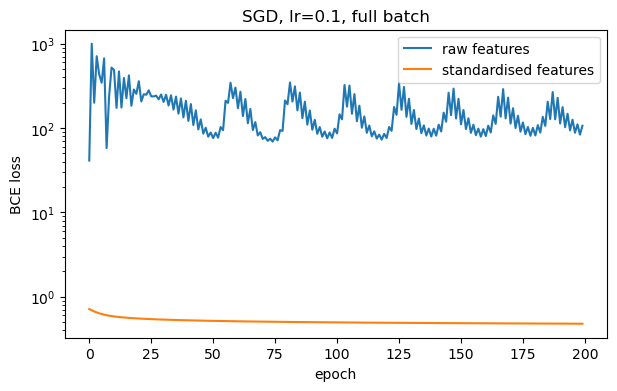

final loss (raw)          = 106.6454
final loss (standardised) = 0.4791
per-feature std: [100.1288833618164 232.27308654785156 1.2809981107711792
 15.236403465270996 43.310028076171875 54.305999755859375 228.076904296875
 0.6224981546401978 0.927582323551178 1.0435662269592285 229.5887908935547
 24.6246280670166 14.617151260375977 9.517152786254883]
largest / smallest = 373.1x


In [7]:
def train_logreg(X, y, epochs=200, lr=0.1, seed=42):
    torch.manual_seed(seed)                      # same initial weights for both runs
    model = torch.nn.Linear(X.shape[1], 1)
    loss_fn = torch.nn.BCEWithLogitsLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)

    losses = []
    for epoch in range(epochs):
        logits = model(X)                        # forward
        loss = loss_fn(logits, y)
        optimizer.zero_grad()                    # clear old gradients
        loss.backward()                          # backward
        optimizer.step()                         # update
        losses.append(loss.item())
    return model, losses

y = ytr.float().reshape(-1, 1)

Xtr_raw = torch.tensor(X_train, dtype=torch.float32)

model_raw, losses_raw = train_logreg(Xtr_raw, y)

model_std, losses_std = train_logreg(Xtr.float(), y)

plt.figure(figsize=(7, 4))
plt.plot(losses_raw, label="raw features")
plt.plot(losses_std, label="standardised features")
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("BCE loss")
plt.legend()
plt.title("SGD, lr=0.1, full batch")
plt.show()

print(f"final loss (raw)          = {losses_raw[-1]:.4f}")
print(f"final loss (standardised) = {losses_std[-1]:.4f}")

stds = X_train.std(axis=0)
print("per-feature std:", stds)
print(f"largest / smallest = {stds.max() / stds.min():.1f}x")

In [8]:
def train_model(model, epochs=40, lr=1e-3, batch_size=256, verbose=True):
    # Train a binary classifier. Returns per-epoch train and validation losses.
    from torch.utils.data import TensorDataset, DataLoader

    loader    = DataLoader(TensorDataset(Xtr, ytr), batch_size=batch_size, shuffle=True)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn   = nn.BCEWithLogitsLoss()

    train_losses, val_losses = [], []

    for epoch in range(epochs):
        model.train()
        running = 0.0
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            running += loss.item() * len(xb)
        train_losses.append(running / len(Xtr))

        model.eval()
        with torch.no_grad():
            val_losses.append(loss_fn(model(Xva), yva).item())

        if verbose and (epoch % 10 == 0 or epoch == epochs - 1):
            print(f"  epoch {epoch:3d}   train {train_losses[-1]:.4f}   val {val_losses[-1]:.4f}")

    return train_losses, val_losses


def evaluate(model, X, y):
    model.eval()
    with torch.no_grad():
        logits = model(X)
        probs  = torch.sigmoid(logits).numpy().flatten()
    from sklearn.metrics import roc_auc_score
    acc = ((probs > 0.5) == y.numpy().flatten()).mean()
    return probs, roc_auc_score(y.numpy().flatten(), probs), acc

In [9]:
print(f"training a linear model on {n_features} features\n")

torch.manual_seed(42)
linear_model = nn.Linear(n_features, 1)
lin_train, lin_val = train_model(linear_model, epochs=40, lr=1e-2)   # convex: larger step is safe

lin_probs, lin_auc, lin_acc = evaluate(linear_model, Xte, yte)
print(f"\nLINEAR BASELINE:  test AUC = {lin_auc:.4f}   accuracy = {lin_acc:.1%}")

training a linear model on 14 features

  epoch   0   train 0.5027   val 0.4640
  epoch  10   train 0.4340   val 0.4315
  epoch  20   train 0.4287   val 0.4276
  epoch  30   train 0.4259   val 0.4254
  epoch  39   train 0.4245   val 0.4244

LINEAR BASELINE:  test AUC = 0.8900   accuracy = 81.1%


In [10]:
from torch.utils.data import TensorDataset, DataLoader

demo_loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=4, shuffle=True)
xb, yb = next(iter(demo_loader))
print("xb", tuple(xb.shape), "  yb", tuple(yb.shape), "  labels", yb.flatten().tolist())

xb (4, 14)   yb (4, 1)   labels [1.0, 1.0, 0.0, 1.0]


In [11]:
Xtr_t = Xtr.float()
ytr_t = ytr.float().reshape(-1, 1)

dataset = TensorDataset(Xtr_t, ytr_t)
loader  = DataLoader(dataset, batch_size=256, shuffle=True)

N_train = len(dataset)
expected = (N_train + 256 - 1) // 256
print(f"batches per epoch = {len(loader)}")
print(f"ceil(N_train / 256) = {expected}")
assert len(loader) == expected

for i, (xb, yb) in enumerate(loader):
    print(f"batch {i}: xb {tuple(xb.shape)}, yb {tuple(yb.shape)}")
    if i == 2:
        break

torch.manual_seed(42)
model     = torch.nn.Linear(Xtr_t.shape[1], 1)
loss_fn   = torch.nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)

epoch_losses = []
for epoch in range(30):
    running = 0.0
    for xb, yb in loader:
        logits = model(xb)                      # 1. forward
        loss   = loss_fn(logits, yb)

batches per epoch = 222
ceil(N_train / 256) = 222
batch 0: xb (256, 14), yb (256, 1)
batch 1: xb (256, 14), yb (256, 1)
batch 2: xb (256, 14), yb (256, 1)


In [12]:
torch.manual_seed(42)

mlp = nn.Sequential(
    nn.Linear(n_features, 64), nn.ReLU(),
    nn.Linear(64, 32),         nn.ReLU(),
    nn.Linear(32, 1),                       # NO sigmoid: BCEWithLogitsLoss applies it
)

n_params = sum(p.numel() for p in mlp.parameters())
print(mlp)
print(f"\ntrainable parameters: {n_params:,}")

Sequential(
  (0): Linear(in_features=14, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=1, bias=True)
)

trainable parameters: 3,073


name          params    test AUC
--------------------------------
linear            15      0.8900
tiny             129      0.9820
medium         3,073      0.9924
large         45,057      0.9916


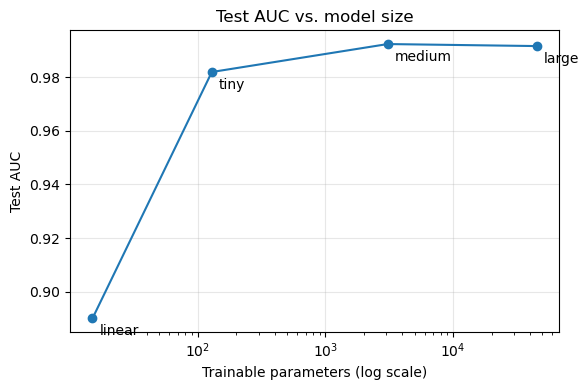

In [13]:
def make_mlp(hidden, n_in=None, n_out=1):
    """Build an nn.Sequential from a list of hidden sizes (empty list -> linear model)."""
    n_in = n_in if n_in is not None else X_train.shape[1]   # full feature set
    layers, prev = [], n_in
    for h in hidden:
        layers += [nn.Linear(prev, h), nn.ReLU()]
        prev = h
    layers.append(nn.Linear(prev, n_out))
    return nn.Sequential(*layers)

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

configs = {
    "linear": dict(hidden=[],             lr=1e-2),
    "tiny":   dict(hidden=[8],            lr=1e-3),
    "medium": dict(hidden=[64, 32],       lr=1e-3),
    "large":  dict(hidden=[256, 128, 64], lr=1e-3),
}

results = []
for name, cfg in configs.items():
    torch.manual_seed(42)
    model = make_mlp(cfg["hidden"])
    n_params = count_params(model)

    train_model(model, epochs=40, lr=cfg["lr"], verbose=False)
    _, auc, _ = evaluate(model, Xte, yte)

    results.append((name, n_params, auc))

print(f"{'name':<10}{'params':>10}{'test AUC':>12}")
print("-" * 32)
for name, n, auc in results:
    print(f"{name:<10}{n:>10,}{auc:>12.4f}")

names, params, aucs = zip(*results)
plt.figure(figsize=(6, 4))
plt.plot(params, aucs, "o-")
for nm, p, a in results:
    plt.annotate(nm, (p, a), textcoords="offset points", xytext=(5, -12))
plt.xscale("log")
plt.xlabel("Trainable parameters (log scale)")
plt.ylabel("Test AUC")
plt.title("Test AUC vs. model size")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
mlp_train, mlp_val = train_model(mlp, epochs=40, lr=1e-3)

mlp_probs, mlp_auc, mlp_acc = evaluate(mlp, Xte, yte)
print(f"\nLINEAR      test AUC = {lin_auc:.4f}   accuracy = {lin_acc:.1%}")
print(f"NEURAL NET  test AUC = {mlp_auc:.4f}   accuracy = {mlp_acc:.1%}")

  epoch   0   train 0.3588   val 0.2280
  epoch  10   train 0.1227   val 0.1245
  epoch  20   train 0.1088   val 0.1130
  epoch  30   train 0.1022   val 0.1072
  epoch  39   train 0.0995   val 0.1052

LINEAR      test AUC = 0.8900   accuracy = 81.1%
NEURAL NET  test AUC = 0.9922   accuracy = 96.6%


In [15]:
from sklearn.metrics import roc_auc_score
from torch.utils.data import TensorDataset, DataLoader

i_m4mu = FEATURE_NAMES.index("m4mu")
Xtr_1, Xva_1, Xte_1 = Xtr[:, [i_m4mu]], Xva[:, [i_m4mu]], Xte[:, [i_m4mu]]


def quick_train(model, Xa, ya, Xb_, yb_, epochs=30, lr=1e-3):
    loader = DataLoader(TensorDataset(Xa, ya), batch_size=256, shuffle=True)
    opt, lf = torch.optim.Adam(model.parameters(), lr=lr), nn.BCEWithLogitsLoss()
    for _ in range(epochs):
        for xb, yb in loader:
            opt.zero_grad(); lf(model(xb), yb).backward(); opt.step()
    with torch.no_grad():
        p = torch.sigmoid(model(Xb_)).numpy().flatten()
    return roc_auc_score(yb_.numpy().flatten(), p)


torch.manual_seed(0)
auc_lin = quick_train(nn.Linear(1, 1), Xtr_1, ytr, Xte_1, yte, lr=1e-2)

torch.manual_seed(0)
mlp_1 = nn.Sequential(nn.Linear(1, 16), nn.ReLU(), nn.Linear(16, 16), nn.ReLU(), nn.Linear(16, 1))
auc_mlp = quick_train(mlp_1, Xtr_1, ytr, Xte_1, yte)

print(f"   MLP (2 hidden layers)  : test AUC = {auc_mlp:.4f}")

   MLP (2 hidden layers)  : test AUC = 0.9831


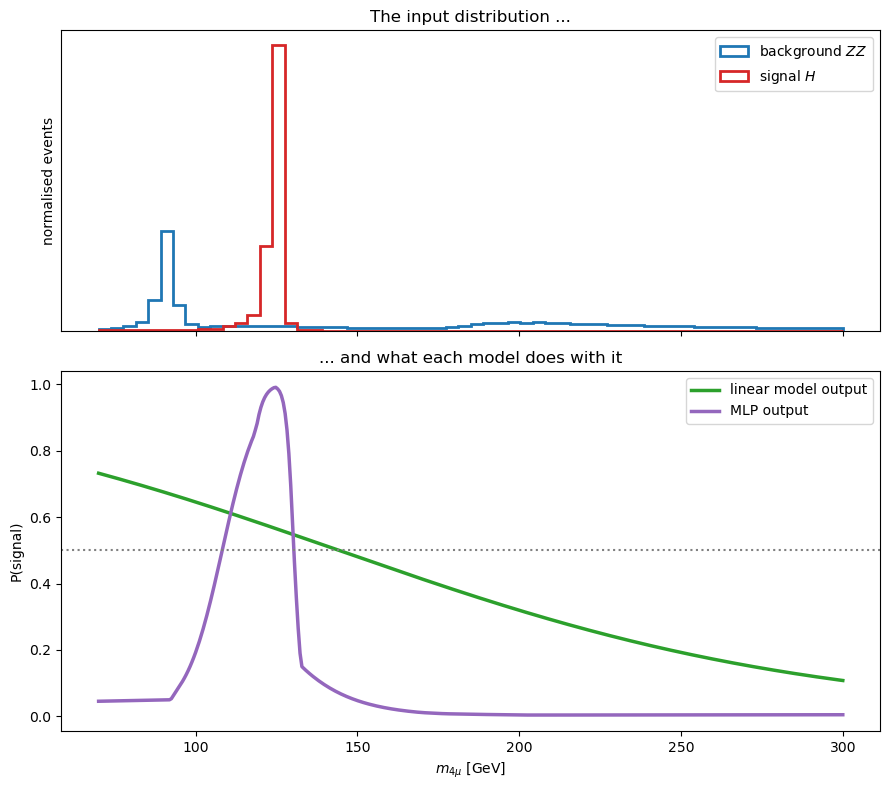

In [16]:
# Evaluate both trained models on a grid of m4mu values, standardised the same way
# the training data was.
grid_raw = np.linspace(70, 300, 400, dtype=np.float32)
grid_std = torch.tensor(((grid_raw - mean[i_m4mu]) / std[i_m4mu]).reshape(-1, 1))

torch.manual_seed(0)
lin_1 = nn.Linear(1, 1)
quick_train(lin_1, Xtr_1, ytr, Xte_1, yte, lr=1e-2)

with torch.no_grad():
    p_lin = torch.sigmoid(lin_1(grid_std)).numpy().flatten()
    p_mlp = torch.sigmoid(mlp_1(grid_std)).numpy().flatten()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 8), sharex=True,
                               gridspec_kw={"height_ratios": [1, 1.2]})

bins = np.linspace(70, 300, 61)                     # 60 bins
ax1.hist(data["background"]["m4mu"], bins=bins, histtype="step", lw=2, density=True,
         color="tab:blue", label="background $ZZ$")
ax1.hist(data["signal"]["m4mu"], bins=bins, histtype="step", lw=2, density=True,
         color="tab:red", label="signal $H$")
ax1.set_ylabel("normalised events"); ax1.legend(); ax1.set_yticks([])
ax1.set_title("The input distribution ...")

ax2.plot(grid_raw, p_lin, lw=2.5, color="tab:green", label="linear model output")
ax2.plot(grid_raw, p_mlp, lw=2.5, color="tab:purple", label="MLP output")
ax2.axhline(0.5, color="grey", ls=":")
ax2.set_xlabel(r"$m_{4\mu}$ [GeV]"); ax2.set_ylabel("P(signal)")
ax2.legend(); ax2.set_title("... and what each model does with it")
plt.tight_layout(); plt.show()

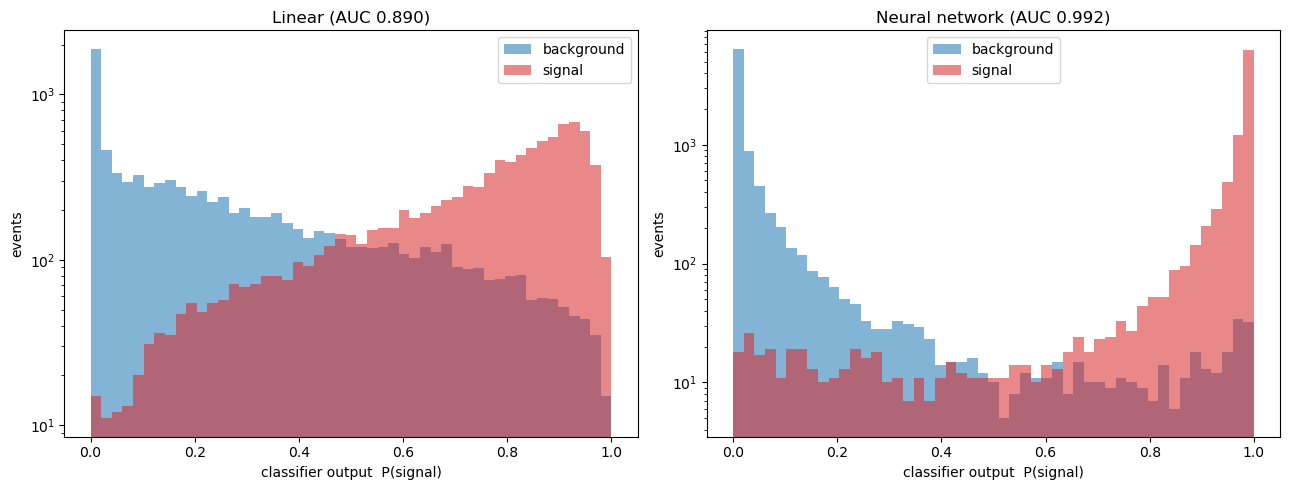

In [17]:
y_true = yte.numpy().flatten()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

bins = np.linspace(0, 1, 50)
for ax, (probs, title) in zip([ax1, ax2],
                              [(lin_probs, f"Linear (AUC {lin_auc:.3f})"),
                               (mlp_probs, f"Neural network (AUC {mlp_auc:.3f})")]):
    ax.hist(probs[y_true == 0], bins=bins, histtype="stepfilled", alpha=0.55,
            color="tab:blue", label="background")
    ax.hist(probs[y_true == 1], bins=bins, histtype="stepfilled", alpha=0.55,
            color="tab:red", label="signal")
    ax.set_xlabel("classifier output  P(signal)"); ax.set_ylabel("events")
    ax.set_title(title); ax.legend(); ax.set_yscale("log")
plt.tight_layout(); plt.show()

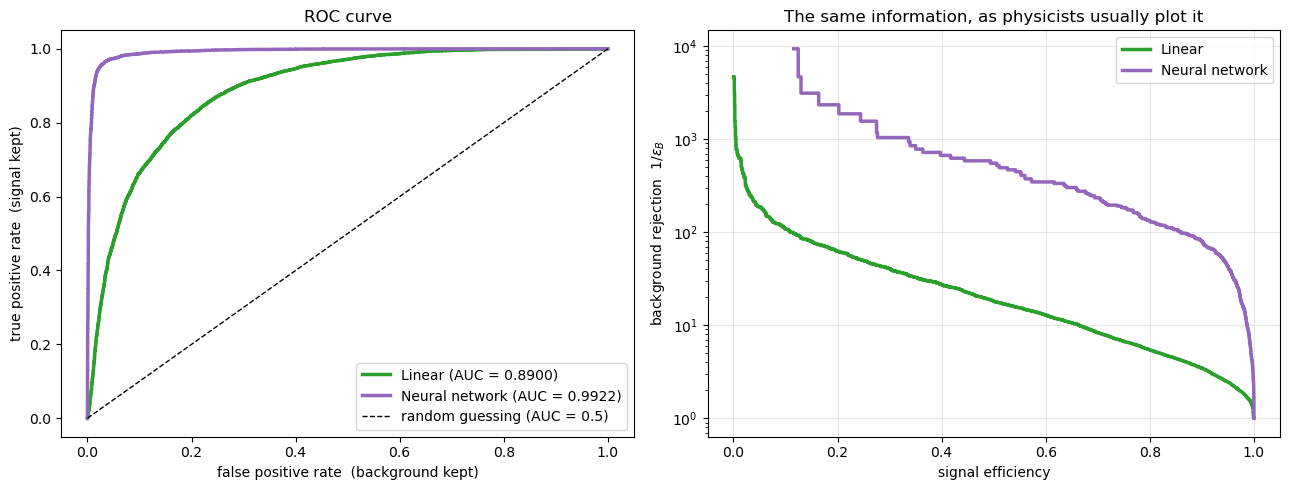

In [18]:
from sklearn.metrics import roc_curve, auc as auc_fn

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

for probs, name, color in [(lin_probs, "Linear",         "tab:green"),
                           (mlp_probs, "Neural network", "tab:purple")]:
    fpr, tpr, thr = roc_curve(y_true, probs)
    ax1.plot(fpr, tpr, lw=2.5, color=color, label=f"{name} (AUC = {auc_fn(fpr, tpr):.4f})")
    with np.errstate(divide="ignore", invalid="ignore"):
        rej = np.where(fpr > 0, 1.0 / np.maximum(fpr, 1e-12), np.nan)
    ax2.plot(tpr, rej, lw=2.5, color=color, label=name)

ax1.plot([0, 1], [0, 1], "k--", lw=1, label="random guessing (AUC = 0.5)")
ax1.set_xlabel("false positive rate  (background kept)")
ax1.set_ylabel("true positive rate  (signal kept)")
ax1.set_title("ROC curve"); ax1.legend(loc="lower right")

ax2.set_yscale("log"); ax2.set_xlabel("signal efficiency")
ax2.set_ylabel("background rejection  $1/\\epsilon_B$")
ax2.set_title("The same information, as physicists usually plot it")
ax2.legend(); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [19]:
probs, auc, _ = evaluate(mlp, Xte, yte)
y = yte.numpy().flatten().astype(int)

fpr, tpr, thresholds = roc_curve(y, probs)

wp = {}
print(f"{'target TPR':>10}{'threshold':>12}{'TPR':>9}{'FPR':>9}{'1/FPR':>10}")
print("-" * 50)
for eff in (0.50, 0.80, 0.95):
    idx = np.argmin(np.abs(tpr - eff))
    wp[eff] = thresholds[idx]
    rej = 1 / fpr[idx] if fpr[idx] > 0 else np.inf
    print(f"{eff:>10.2f}{thresholds[idx]:>12.4f}{tpr[idx]:>9.4f}{fpr[idx]:>9.4f}{rej:>10.1f}")

thr80 = wp[0.80]

sel = probs >= thr80
TP = int(( sel & (y == 1)).sum())
FP = int(( sel & (y == 0)).sum())
FN = int((~sel & (y == 1)).sum())
TN = int((~sel & (y == 0)).sum())

print(f"\nConfusion matrix at thr80 = {thr80:.4f}")
print("            pred bkg  pred sig")
print(f"true bkg  {TN:>9}  {FP:>8}")
print(f"true sig  {FN:>9}  {TP:>8}")

precision = TP / (TP + FP)
recall    = TP / (TP + FN)
print(f"\nprecision = {precision:.4f}")
print(f"recall    = {recall:.4f}")

target TPR   threshold      TPR      FPR     1/FPR
--------------------------------------------------
      0.50      0.9898   0.4995   0.0018     551.5
      0.80      0.9543   0.7998   0.0075     133.9
      0.95      0.6894   0.9500   0.0233      43.0

Confusion matrix at thr80 = 0.9543
            pred bkg  pred sig
true bkg       9305        70
true sig       1905      7610

precision = 0.9909
recall    = 0.7998


In [20]:
seeds = [1, 2, 3, 4, 5]

def seed_study(hidden, lr, epochs=40):
    aucs = []
    for s in seeds:
        torch.manual_seed(s)
        m = make_mlp(hidden)
        train_model(m, epochs=epochs, lr=lr, verbose=False)
        aucs.append(evaluate(m, Xte, yte)[1])
    return np.array(aucs)

aucs_med = seed_study([64, 32], lr=1e-3)
aucs_lin = seed_study([],       lr=1e-2)

for name, a in (("medium", aucs_med), ("linear", aucs_lin)):
    print(f"{name:<7} AUCs: {np.round(a, 4)}")
    print(f"{'':<7} mean = {a.mean():.4f}   std = {np.std(a, ddof=1):.4f}\n")

diff = aucs_med.mean() - aucs_lin.mean()
print(f"mean(medium) - mean(linear) = {diff:.4f}")

medium  AUCs: [0.9919 0.9924 0.9919 0.9911 0.9922]
        mean = 0.9919   std = 0.0005

linear  AUCs: [0.8896 0.8896 0.8897 0.8903 0.8898]
        mean = 0.8898   std = 0.0003

mean(medium) - mean(linear) = 0.1021


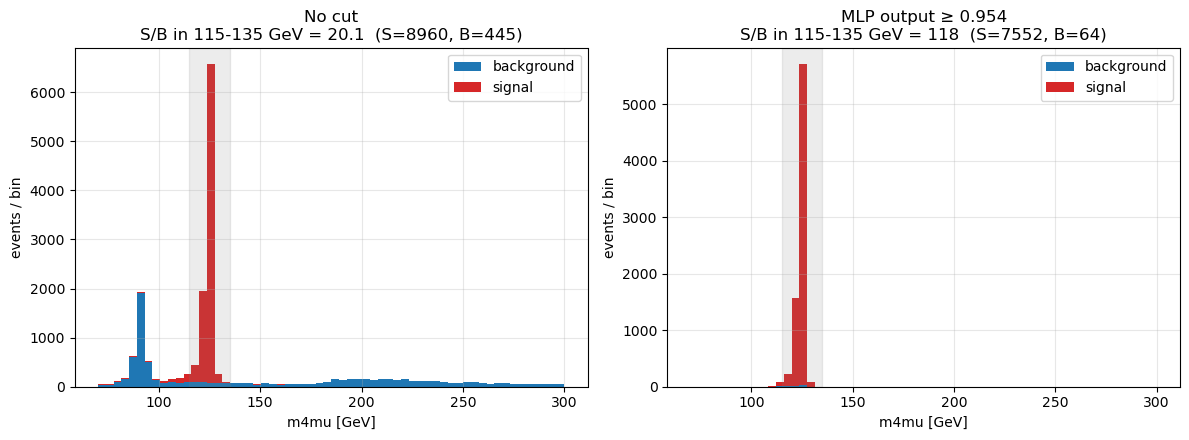

In [21]:
win = (115, 135)

m4mu = np.ma.filled(np.ma.asarray(X_test)[:, FEATURE_NAMES.index("m4mu")].astype(float), np.nan)
mlp_probs, _, _ = evaluate(mlp, Xte, yte)
y = yte.numpy().flatten().astype(int)

bins = np.linspace(70, 300, 61)

def s_over_b(m, yy):
    inw = (m >= win[0]) & (m < win[1])
    S = int((inw & (yy == 1)).sum())
    B = int((inw & (yy == 0)).sum())
    return S, B, (S / B if B > 0 else np.inf)

sel = mlp_probs >= thr80
panels = [
    ("No cut",                 m4mu,       y),
    (f"MLP output ≥ {thr80:.3f}", m4mu[sel], y[sel]),
]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (title, m, yy) in zip(axes, panels):
    S, B, r = s_over_b(m, yy)
    ax.hist([m[yy == 0], m[yy == 1]], bins=bins, stacked=True,
            label=["background", "signal"], color=["tab:blue", "tab:red"])
    ax.axvspan(*win, color="gray", alpha=0.15)
    ax.set_xlabel("m4mu [GeV]")
    ax.set_ylabel("events / bin")
    ax.set_title(f"{title}\nS/B in {win[0]}-{win[1]} GeV = {r:.3g}  (S={S}, B={B})")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
inw = (m4mu >= win[0]) & (m4mu < win[1])

S0, B0 = int((inw & (y == 1)).sum()),        int((inw & (y == 0)).sum())
S1, B1 = int((inw & sel & (y == 1)).sum()),  int((inw & sel & (y == 0)).sum())

print(f"S/B no cut : {S0/B0:.4g}  (S={S0}, B={B0})")
print(f"S/B cut    : {S1/B1:.4g}  (S={S1}, B={B1})")
print(f"improvement factor in window = {(S1/B1)/(S0/B0):.2f}")
print(f"  (equals eff_S/eff_B = {S1/S0:.3f} / {B1/B0:.3f})")

# Signal lost
Sall0, Sall1 = int((y == 1).sum()), int((sel & (y == 1)).sum())
print(f"\nsignal lost in window : {S0 - S1} of {S0}  ({100*(S0 - S1)/S0:.1f}%)")
print(f"signal lost overall   : {Sall0 - Sall1} of {Sall0}  ({100*(Sall0 - Sall1)/Sall0:.1f}%)")

S/B no cut : 20.13  (S=8960, B=445)
S/B cut    : 118  (S=7552, B=64)
improvement factor in window = 5.86
  (equals eff_S/eff_B = 0.843 / 0.144)

signal lost in window : 1408 of 8960  (15.7%)
signal lost overall   : 1905 of 9515  (20.0%)
